# Minería de Datos · Transformación, Escalamiento y Reducción de Dimensionalidad (PCA)

Este cuaderno implementa:
1. Diagnóstico de escala y demostración del efecto de la escala sobre la distancia euclídea (El Gancho).
2. Comparación sistemática de escaladores (`MinMaxScaler`, `StandardScaler`, `RobustScaler`).
3. Codificación de variables categóricas (One-Hot Encoding).
4. Discretización de variables continuas (`KBinsDiscretizer`).
5. Reducción de dimensionalidad con Análisis de Componentes Principales (**PCA**).
6. Exportación de `dataset_reducido.csv` conservando la máxima variabilidad explicada.


## 1. Importación de librerías y clase modular


In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")

from src.transformacion import Transformacion


## 2. Carga del Dataset Integrado y Diagnóstico de Escala


In [3]:
trans = Transformacion("../dataset/dataset_integrado.csv")
df = trans.cargar()
trans.diagnosticar()


Dimensiones: 54,428 filas × 8 columnas

Variables continuas predictoras: ['AÑO', 'VEHICULOS_REGISTRADOS', 'VEHICULOS_RECUPERADOS']
Variables categóricas: ['TIPO_VEHICULO', 'DEPARTAMENTO']
Variable objetivo: VEHICULOS_HURTADOS

Estadísticos descriptivos básicos:
            AÑO  VEHICULOS_REGISTRADOS  VEHICULOS_RECUPERADOS
count  54428.00               54428.00               54428.00
mean    2002.83                 346.12                   3.06
std       20.48                1186.25                   9.18
min     1902.00                   0.00                   0.00
25%     1991.00                   0.00                   0.00
50%     2010.00                   4.00                   0.00
75%     2019.00                  93.00                   2.00
max     2026.00                8513.12                  68.00


## 3. El Gancho: La columna que secuestró la distancia
Demostración de cómo variables con magnitudes dispares (ej. Parque Automotor de miles de registros vs. Hurtos en unidades) distorsionan métricas euclídeas en algoritmos como k-NN o K-Means.


In [4]:
resumen_distancia = trans.demostrar_impacto_distancia()
for k, v in resumen_distancia.items():
    print(f"• {k}: {v}")


• municipio_a: SAN PEDRO DE CARTAGO
• municipio_b: NEIVA
• distancia_sin_escalar: 1636.19
• distancia_escalada_minmax: 0.4148
• conclusion: Sin escalamiento, la variable con mayor varianza domina el 99%+ de la distancia euclídea.


## 4. Comparación de Métodos de Escalamiento
Evaluación de `MinMaxScaler` ([0, 1]), `StandardScaler` (Z-score: media=0, std=1) y `RobustScaler` (mediana=0, IQR).


In [5]:
df_minmax, df_std, df_rob = trans.comparar_escaladores()

print("--- 1. MinMaxScaler ---")
display(df_minmax.describe().round(3))

print("--- 2. StandardScaler ---")
display(df_std.describe().round(3))

print("--- 3. RobustScaler (Óptimo ante valores atípicos y grandes capitales) ---")
display(df_rob.describe().round(3))


--- 1. MinMaxScaler ---


,AÑO_minmax,VEHICULOS_REGISTRADOS_minmax,VEHICULOS_RECUPERADOS_minmax
count,54428.000,54428.000,54428.000
mean,0.813,0.041,0.045
std,0.165,0.139,0.135
min,0.000,0.000,0.000
25%,0.718,0.000,0.000
50%,0.871,0.000,0.000
75%,0.944,0.011,0.029
max,1.000,1.000,1.000


--- 2. StandardScaler ---


,AÑO_std,VEHICULOS_REGISTRADOS_std,VEHICULOS_RECUPERADOS_std
count,54428.000,54428.000,54428.000
mean,0.000,0.000,0.000
std,1.000,1.000,1.000
min,-4.923,-0.292,-0.334
25%,-0.578,-0.292,-0.334
50%,0.350,-0.288,-0.334
75%,0.790,-0.213,-0.116
max,1.131,6.885,7.074


--- 3. RobustScaler (Óptimo ante valores atípicos y grandes capitales) ---


,AÑO_rob,VEHICULOS_REGISTRADOS_rob,VEHICULOS_RECUPERADOS_rob
count,54428.000,54428.000,54428.000
mean,-0.256,3.679,1.532
std,0.732,12.755,4.590
min,-3.857,-0.043,0.000
25%,-0.679,-0.043,0.000
50%,0.000,0.000,0.000
75%,0.321,0.957,1.000
max,0.571,91.496,34.000


## 5. Codificación de Variables Categóricas (One-Hot Encoding)
Conversión de variables nominales (`TIPO_VEHICULO`, `DEPARTAMENTO`) evitando introducir órdenes arbitrarios.


In [6]:
df_dummies = trans.codificar_onehot()
print(f"Variables generadas tras One-Hot: {df_dummies.shape[1]}")
df_dummies.head()


Variables generadas tras One-Hot: 35


,TIPO_VEHICULO_AUTOMOTOR,TIPO_VEHICULO_MOTOCICLETA,DEPARTAMENTO_AMAZONAS,DEPARTAMENTO_ANTIOQUIA,DEPARTAMENTO_ARAUCA,DEPARTAMENTO_ATLANTICO,DEPARTAMENTO_BOGOTA D.C.,DEPARTAMENTO_BOLIVAR,DEPARTAMENTO_BOYACA,DEPARTAMENTO_CALDAS,...,DEPARTAMENTO_PUTUMAYO,DEPARTAMENTO_QUINDIO,DEPARTAMENTO_RISARALDA,DEPARTAMENTO_SAN ANDRES ISLAS,DEPARTAMENTO_SANTANDER,DEPARTAMENTO_SUCRE,DEPARTAMENTO_TOLIMA,DEPARTAMENTO_VALLE DEL CAUCA,DEPARTAMENTO_VAUPES,DEPARTAMENTO_VICHADA
0,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 6. Discretización de Variables Continuas (KBinsDiscretizer)
Segmentación por cuantiles para análisis de negocio en cohortes temporales.


In [7]:
serie_bin_anio, bordes_anio = trans.discretizar(columna="AÑO", n_bins=4)
print("Puntos de corte (bordes) para AÑO:", bordes_anio)
print("Distribución de registros por intervalo:")
print(serie_bin_anio.value_counts().sort_index())


Puntos de corte (bordes) para AÑO: [1902. 1991. 2010. 2019. 2026.]
Distribución de registros por intervalo:
AÑO_BIN
0.0    13439
1.0    13412
2.0    13595
3.0    13982
Name: count, dtype: int64


/Users/camilapava/pinokio/bin/miniforge/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


## 7. Reducción de Dimensionalidad con PCA
Aplicación de Análisis de Componentes Principales para sintetizar la varianza continua y remover multicolinealidad.


In [8]:
df_pca, resumen_pca = trans.aplicar_pca(n_componentes=5)
print("Componentes seleccionadas:", resumen_pca["n_componentes"])
print("Varianza individual explicada:", resumen_pca["varianza_individual"])
print("Varianza acumulada:", resumen_pca["varianza_acumulada"])
print(f"Varianza total retenida: {resumen_pca['pct_total_explicado']}%")


Componentes seleccionadas: 3
Varianza individual explicada: [0.5082, 0.2958, 0.196]
Varianza acumulada: [0.5082, 0.804, 1.0]
Varianza total retenida: 100.0%


### 7.1 Visualización: Scree Plot (Varianza Explicada Acumulada)


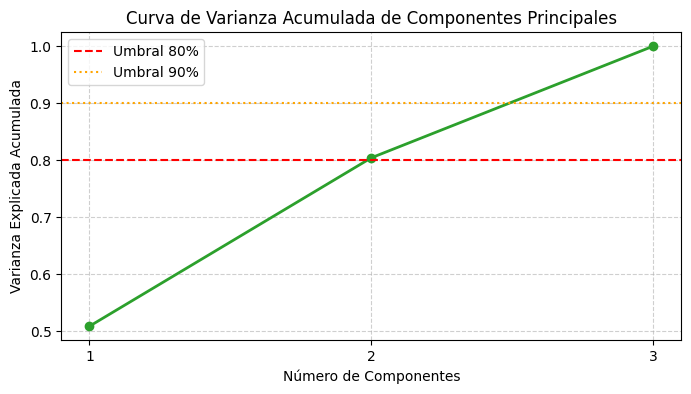

In [9]:
plt.figure(figsize=(8, 4))
n_comps = len(resumen_pca["varianza_acumulada"])
plt.plot(range(1, n_comps + 1), resumen_pca["varianza_acumulada"], marker="o", color="#2ca02c", linewidth=2)
plt.axhline(0.80, color="r", linestyle="--", label="Umbral 80%")
plt.axhline(0.90, color="orange", linestyle=":", label="Umbral 90%")
plt.title("Curva de Varianza Acumulada de Componentes Principales")
plt.xlabel("Número de Componentes")
plt.ylabel("Varianza Explicada Acumulada")
plt.xticks(range(1, n_comps + 1))
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


### 7.2 Proyección 2D: Primeros dos componentes (PC1 vs PC2)


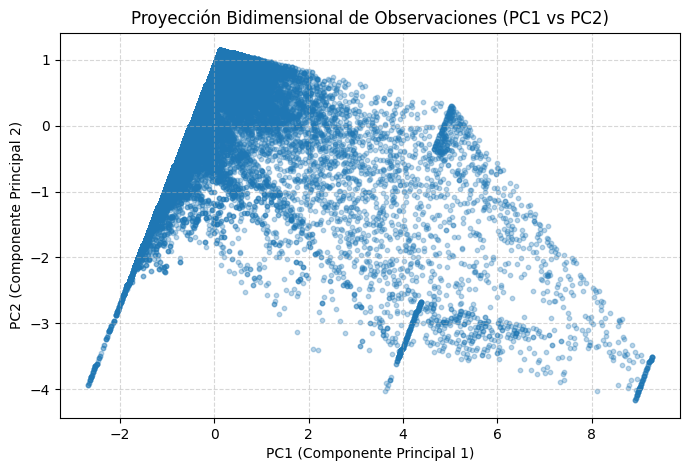

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.3, c="#1f77b4", s=10)
plt.title("Proyección Bidimensional de Observaciones (PC1 vs PC2)")
plt.xlabel("PC1 (Componente Principal 1)")
plt.ylabel("PC2 (Componente Principal 2)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


## 8. Exportación del Dataset Reducido
Se genera el archivo final `dataset/dataset_reducido.csv` conteniendo identificadores administrativos, las componentes principales calculadas y la variable objetivo.


In [11]:
df_reducido, _ = trans.generar_dataset_reducido()
trans.guardar_reducido("../dataset/dataset_reducido.csv")
print("Muestra del dataset reducido final:")
df_reducido.head(10)


✅ Dataset reducido guardado exitosamente en: ../dataset/dataset_reducido.csv
Dimensiones finales: 54,428 filas × 9 columnas
Muestra del dataset reducido final:


,AÑO,CODIGO_DANE_MUNICIPIO,DEPARTAMENTO,MUNICIPIO,TIPO_VEHICULO,PC1,PC2,PC3,VEHICULOS_HURTADOS
0,1902,13683,BOLIVAR,SANTA ROSA,AUTOMOTOR,-2.672917,-3.940664,1.325378,0.0
1,1902,17653,CALDAS,SALAMINA,MOTOCICLETA,-2.672917,-3.940664,1.325378,0.0
2,1902,76895,VALLE DEL CAUCA,ZARZAL,MOTOCICLETA,-2.672917,-3.940664,1.325378,0.0
3,1903,47745,MAGDALENA,SITIONUEVO,MOTOCICLETA,-2.650300,-3.899674,1.311525,0.0
4,1903,54001,NORTE DE SANTANDER,CUCUTA,AUTOMOTOR,-2.649801,-3.900122,1.311014,0.0
5,1904,17653,CALDAS,SALAMINA,MOTOCICLETA,-2.627682,-3.858683,1.297672,0.0
6,1904,23350,CORDOBA,LA APARTADA,MOTOCICLETA,-2.627682,-3.858683,1.297672,0.0
7,1904,54001,NORTE DE SANTANDER,CUCUTA,AUTOMOTOR,-2.627682,-3.858683,1.297672,0.0
8,1904,68081,SANTANDER,BARRANCABERMEJA,MOTOCICLETA,-2.627682,-3.858683,1.297672,0.0
9,1904,68755,SANTANDER,SOCORRO,MOTOCICLETA,-2.627682,-3.858683,1.297672,0.0
